# Dated works and floruits
How many individuals can be placed in time by their works or by a floruit, and in which centuries.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import polars as pl
from style import *

DB_PATH = '../data/cultura/humans_clean_non_enriched_v3.duckdb'

FIRST_CENTURY = -1000
LAST_CENTURY = 2000
PRECISE = ['day', 'month', 'year', 'decade']
MID_DECADE = 5

pl.Config.set_tbl_rows(40)
pl.Config.set_fmt_str_lengths(80)

SERIES_COLORS = {
    'At least 2 precise works': BLUE,
    'Only 1 precise work': LIGHT_BLUE,
    '"fl." in description': ORANGE,
    'Only 1 precise floruit': GREEN,
    'Only 1 precise floruit, no birth or death': LIGHT_GREEN,
}

apply_style()

connection = duckdb.connect(DB_PATH, read_only=True)

## Load the data
A work's date is its publication date, else its inception, as for `works_period`. A decade-precise date is moved to the middle of its decade. Each individual gets one row: dated works, precise dated works, earliest precise work year.

In [2]:
works = connection.execute('''
    WITH dated AS (
        SELECT individual_work.qid,
               individual_work.work_qid,
               coalesce(work.publication_date.year, work.inception.year) AS year,
               CASE WHEN work.publication_date.year IS NOT NULL THEN work.publication_date.precision
                    ELSE work.inception.precision END AS precision
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
        WHERE coalesce(work.publication_date.year, work.inception.year) IS NOT NULL
    )
    SELECT qid,
           count(DISTINCT work_qid) AS dated_works,
           count(DISTINCT work_qid) FILTER (WHERE precision IN ('day', 'month', 'year', 'decade')) AS precise_works,
           min(CASE WHEN precision = 'decade' THEN year + 5 ELSE year END)
               FILTER (WHERE precision IN ('day', 'month', 'year', 'decade')) AS first_precise_year
    FROM dated
    GROUP BY qid
''').pl()
print(f'{len(works):,} individuals with at least one dated work')
works.sample(5, seed=0)

2,780,765 individuals with at least one dated work


qid,dated_works,precise_works,first_precise_year
str,i64,i64,i64
"""Q82321888""",3,3,2011
"""Q88059702""",1,1,2017
"""Q57355425""",15,15,2011
"""Q46331814""",17,17,2014
"""Q9092435""",1,1,1989


In [3]:
floruit = connection.execute('''
    SELECT entity.qid AS qid,
           entity.description AS description,
           list_distinct([CASE WHEN date.precision = 'decade' THEN date.year + 5 ELSE date.year END
                          FOR date IN floruit_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS precise_years,
           len(birth_date) > 0 OR len(death_date) > 0 AS has_birth_or_death
    FROM individual
    WHERE len(floruit_date) > 0 OR regexp_matches(entity.description, '\\bfl\\.')
''').pl()
print(f'{len(floruit):,} individuals with a floruit property or "fl." in their description')
floruit.sample(5, seed=0)

74,337 individuals with a floruit property or "fl." in their description


qid,description,precise_years,has_birth_or_death
str,str,list[i64],bool
"""Q12305362""","""Danish painter (1841-1893)""",[1874],true
"""Q126961641""",null,[1990],false
"""Q125521114""",null,[1898],false
"""Q104243633""","""ancient Greek astronomer""",[],false
"""Q135241319""",null,[1930],false


In [4]:
def by_century(frame, year_column):
    in_range = frame.with_columns((pl.col(year_column) // 100 * 100).alias('century_start')).filter(
        pl.col('century_start').is_between(FIRST_CENTURY, LAST_CENTURY))
    print(f'{frame.height - in_range.height:,} individuals outside {FIRST_CENTURY}–{LAST_CENTURY + 99} or without a year left out of the table')
    return in_range.group_by('century_start').len('individuals').sort('century_start')


def plot_centuries(series):
    fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
    for name, frame in series.items():
        frame = frame.filter(pl.col('individuals') > 0)
        ax.plot(frame['century_start'], frame['individuals'], marker='o', markersize=5, color=SERIES_COLORS[name], label=name)
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(THOUSANDS)
    ax.set_xlim(FIRST_CENTURY - 50, LAST_CENTURY + 50)
    ax.set_xlabel('Century (start year)')
    ax.grid(axis='y')
    ax.legend(loc='upper left')
    plt.show()

## 1. Individuals with at least two dated works

In [5]:
two_dated = works.filter(pl.col('dated_works') >= 2)
two_precise = works.filter(pl.col('precise_works') >= 2)
print(f'{two_dated.height:,} individuals with at least 2 dated works (any precision)')
print(f'{two_precise.height:,} of them with at least 2 works dated to the year or decade')
assert two_precise.height <= two_dated.height

1,794,294 individuals with at least 2 dated works (any precision)
1,789,214 of them with at least 2 works dated to the year or decade


### By century of their first precise work

In [6]:
two_precise_century = by_century(two_precise, 'first_precise_year')
two_precise_century

7 individuals outside -1000–2099 or without a year left out of the table


century_start,individuals
i64,u32
-900,1
-800,2
-700,2
-600,14
-500,35
-400,23
-300,7
-200,3
-100,14


### Figure: individuals with at least 2 precise works, by century

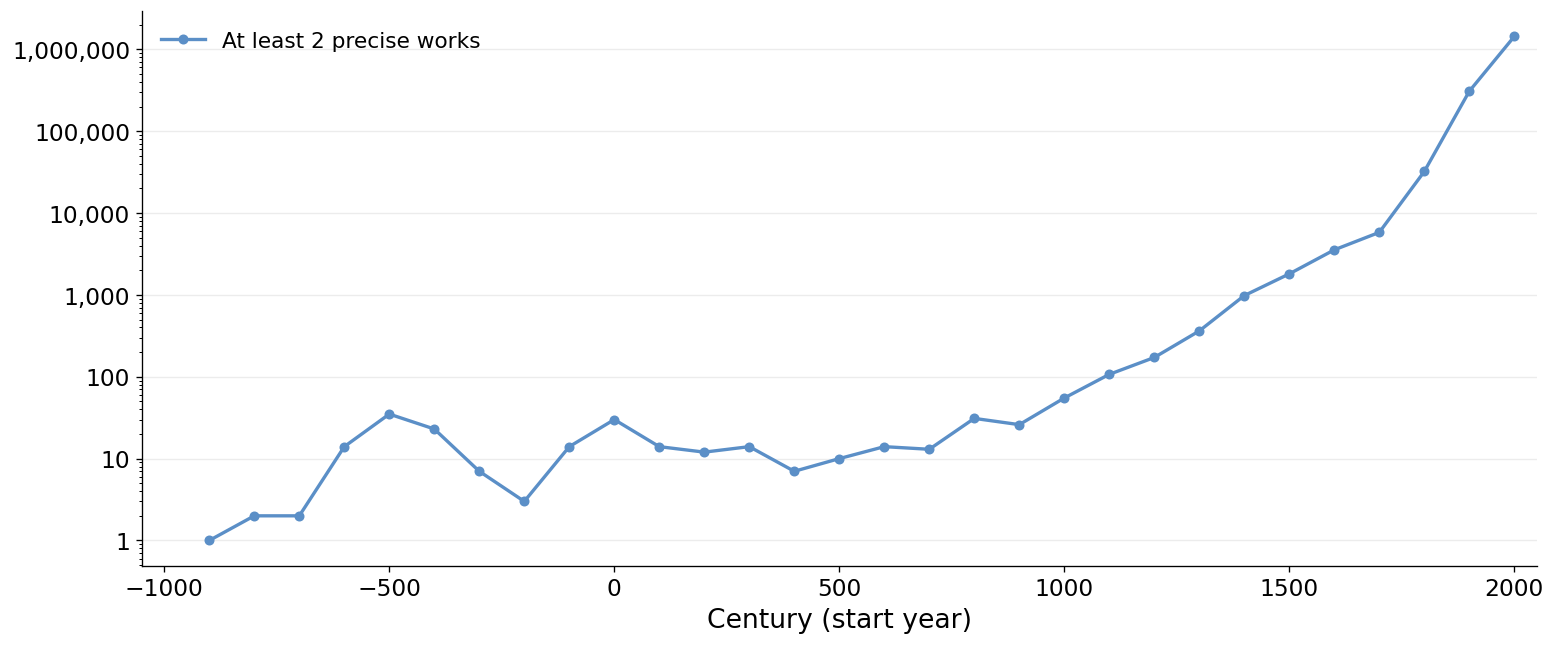

In [7]:
plot_centuries({'At least 2 precise works': two_precise_century})

## 2. Individuals with "fl." in their description
The year is the first one written after "fl." ("fl. 1545-1565" → 1545; "fl. 1930s" → 1935; BC when "BC" or "BCE" follows). A description that gives only a century ("fl. 5th century", "fl. 15. century") has no year.

In [8]:
fl_pattern = r'\bfl\.\s*(?:c\.|ca\.|circa|about|in the|around)?\s*(\d{1,4})(s?)\b(?:[^,;)]*?\b(BCE?)\b)?'
fl_text = (
    floruit.filter(pl.col('description').str.contains(r'\bfl\.'))
    .with_columns(pl.col('description').str.extract_groups(fl_pattern).alias('match'))
    .with_columns(
        pl.col('match').struct.field('1').cast(pl.Int64).alias('year'),
        pl.col('match').struct.field('2').eq('s').alias('is_decade'),
        pl.col('match').struct.field('3').is_not_null().alias('is_bc'),
        pl.col('description').str.contains(r'\bfl\.\s*\d{1,2}\.').alias('is_ordinal_century'),
    )
    .with_columns(
        pl.when(pl.col('is_decade')).then(pl.col('year') + MID_DECADE).otherwise(pl.col('year')).alias('year'))
    .with_columns(pl.when(pl.col('is_bc')).then(-pl.col('year')).otherwise(pl.col('year')).alias('fl_year'))
    .with_columns(pl.when(pl.col('is_ordinal_century')).then(None).otherwise(pl.col('fl_year')).alias('fl_year'))
    .drop('match', 'is_decade', 'is_bc', 'is_ordinal_century', 'year')
)
print(f'{fl_text.height:,} individuals with "fl." in their description')
print(f"{fl_text.filter(pl.col('fl_year').is_not_null()).height:,} of them with a year after it")
fl_text.select('description', 'fl_year').sample(10, seed=1)

7,837 individuals with "fl." in their description
7,257 of them with a year after it


description,fl_year
str,i64
"""born:1685|died:1768-07-07|; Prault; Prault, Pierre, fl. 1711-1766?; Prault, Pier…",1711
"""(fl. 1822)""",1822
"""Italian publisher and bookseller (fl. 1656-1673)""",1656
"""(fl.1619-1648)""",1619
"""Italian printer (fl. 1681-1698)""",1681
"""ichthyologist fl. 1992""",1992
"""Italian printer (fl. 1817-1822)""",1817
"""Etcher and miniature painter, fl. 1764-71""",1764
"""planter and enslaver of Woodford County, Ky (fl. 1816-1864)""",1816


### By century of the year in the description

In [9]:
fl_century = by_century(fl_text, 'fl_year')
fl_century

582 individuals outside -1000–2099 or without a year left out of the table


century_start,individuals
i64,u32
-600,2
-500,4
-400,5
-300,2
-200,2
-100,2
0,4
100,6
200,2


### Figure: individuals with "fl." in their description, by century

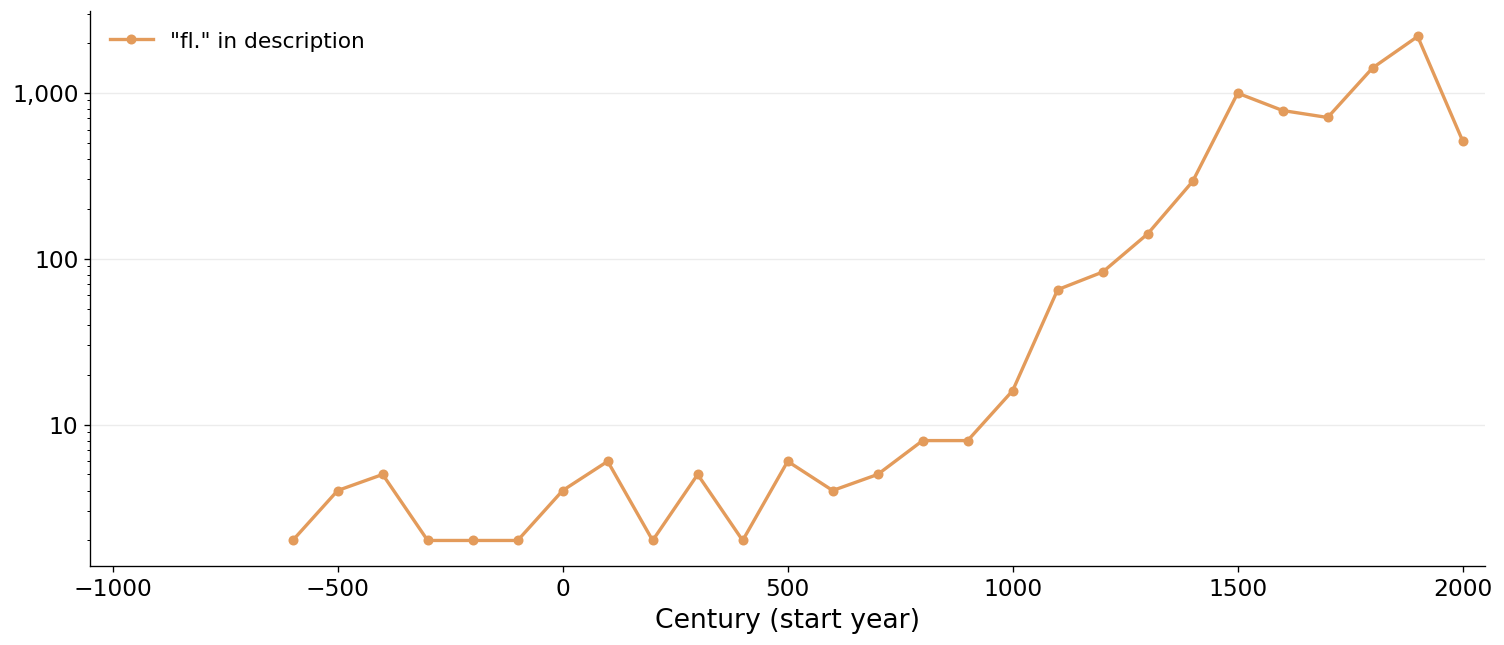

In [10]:
plot_centuries({'"fl." in description': fl_century})

## 3. Individuals with only one floruit date precise to the year or decade
One distinct year across their floruit dates. The last column counts those who also have no birth or death date.

In [11]:
one_floruit = floruit.filter(pl.col('precise_years').list.len() == 1).with_columns(
    pl.col('precise_years').list.first().alias('floruit_year'))
print(f'{one_floruit.height:,} individuals with exactly one year- or decade-precise floruit')
print(f"{one_floruit.filter(~pl.col('has_birth_or_death')).height:,} of them with no birth or death date")

55,835 individuals with exactly one year- or decade-precise floruit
36,029 of them with no birth or death date


### By century of the floruit

In [12]:
one_floruit_century = by_century(one_floruit, 'floruit_year').join(
    by_century(one_floruit.filter(~pl.col('has_birth_or_death')), 'floruit_year').rename({'individuals': 'without_birth_or_death'}),
    on='century_start', how='left',
).fill_null(0)
one_floruit_century

63 individuals outside -1000–2099 or without a year left out of the table
31 individuals outside -1000–2099 or without a year left out of the table


century_start,individuals,without_birth_or_death
i64,u32,u32
-1000,1,1
-800,5,0
-700,2,2
-600,31,14
-500,58,34
-400,72,35
-300,51,32
-200,70,40
-100,73,42


### Figure: individuals with only one precise floruit, by century

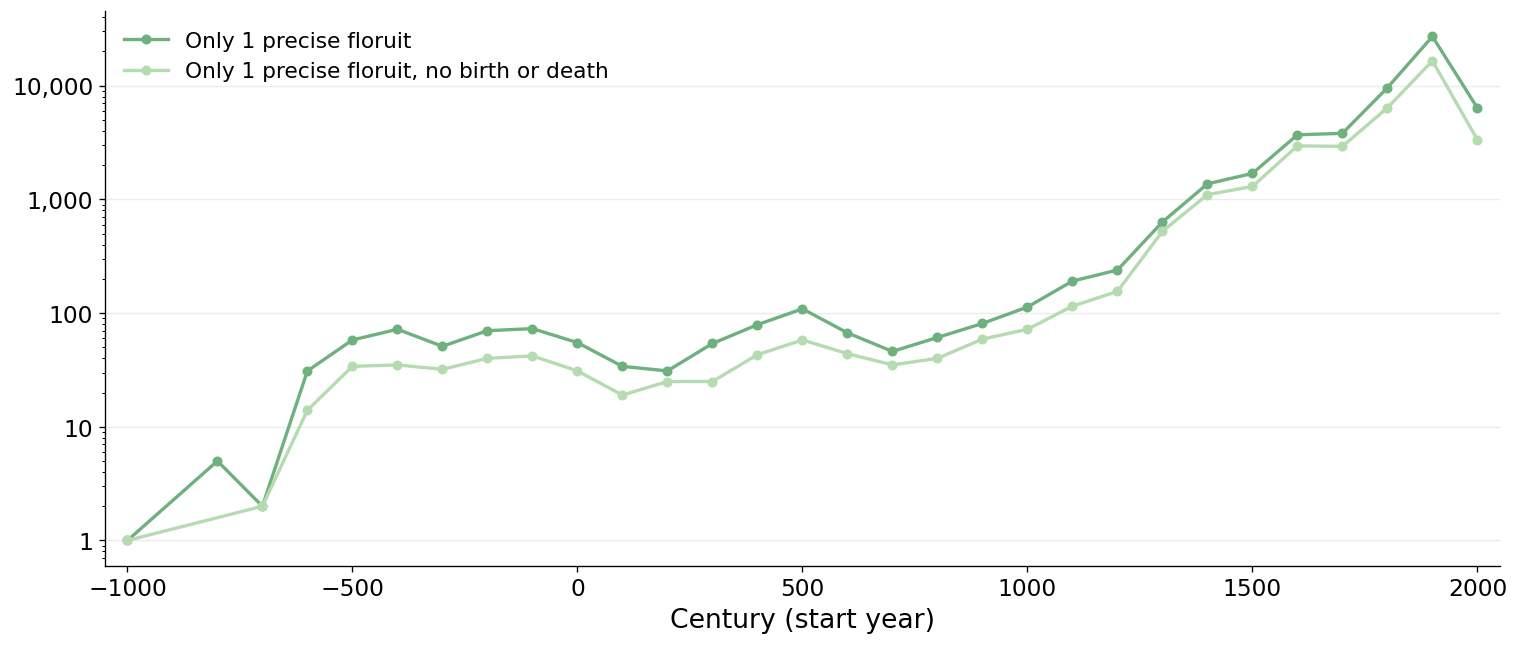

In [13]:
plot_centuries({
    'Only 1 precise floruit': one_floruit_century,
    'Only 1 precise floruit, no birth or death': one_floruit_century.select('century_start', pl.col('without_birth_or_death').alias('individuals')),
})

## 4. Individuals with only one work dated to the year or decade

In [14]:
one_work = works.filter(pl.col('precise_works') == 1)
print(f'{one_work.height:,} individuals with exactly one year- or decade-precise work')

984,063 individuals with exactly one year- or decade-precise work


### By century of that work

In [15]:
one_work_century = by_century(one_work, 'first_precise_year')
one_work_century

11 individuals outside -1000–2099 or without a year left out of the table


century_start,individuals
i64,u32
-900,1
-700,2
-600,33
-500,37
-400,45
-300,4
-200,8
-100,18
0,12


### Figure: individuals with only one precise work, by century

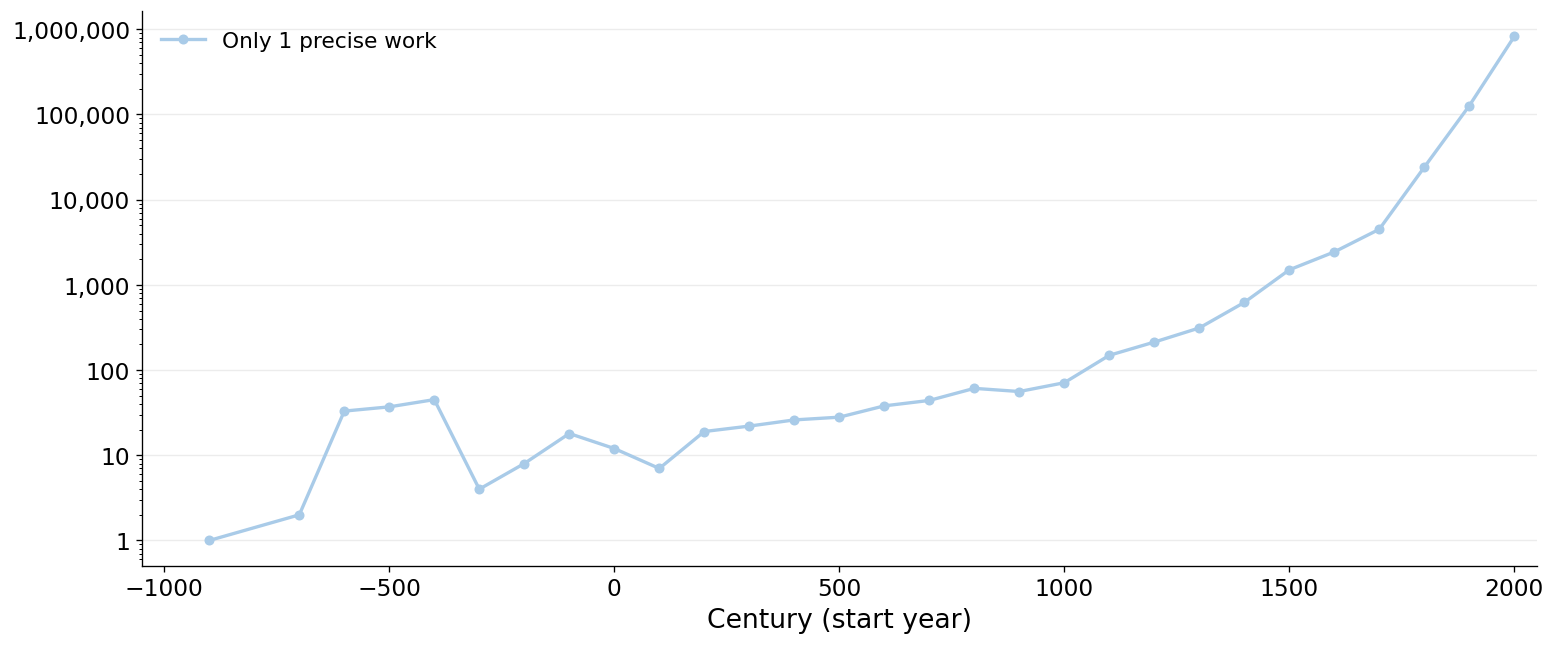

In [16]:
plot_centuries({'Only 1 precise work': one_work_century})

## Summary by century

### Figure: the four groups together

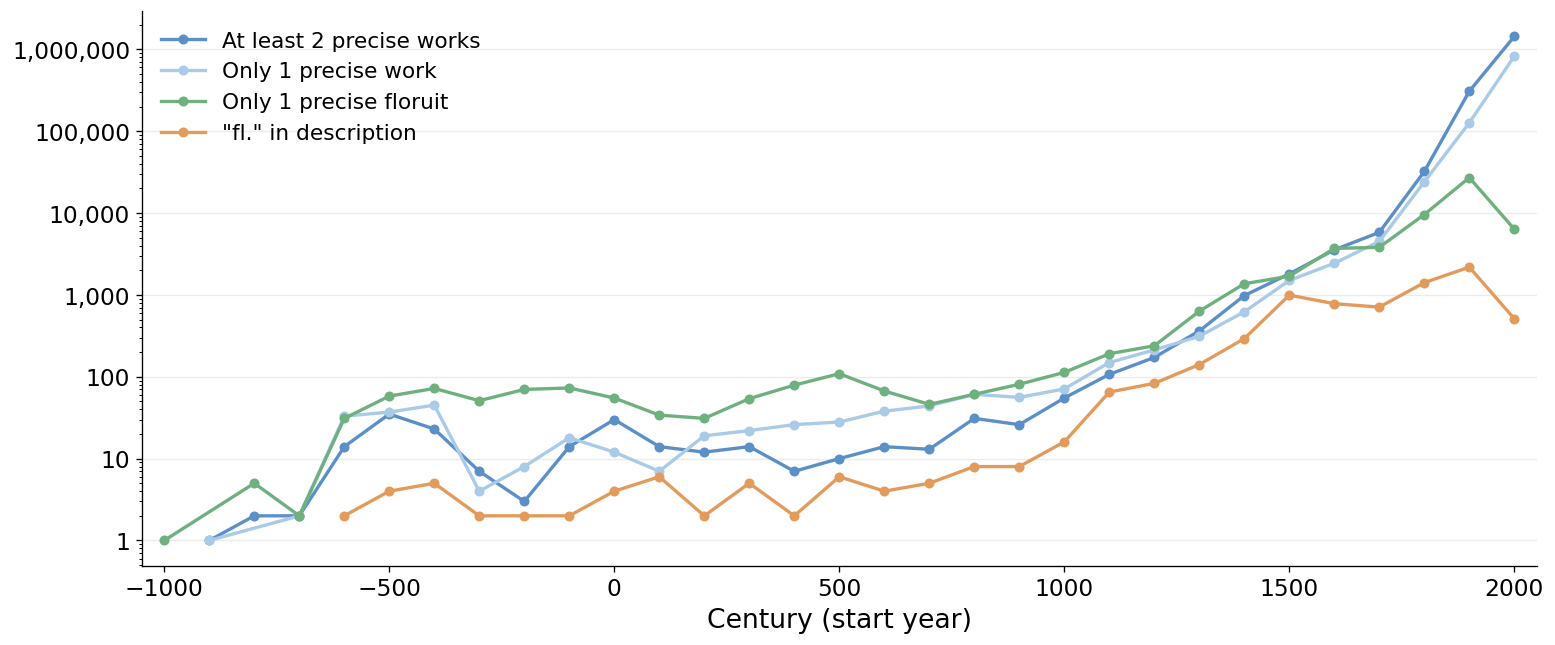

In [17]:
plot_centuries({
    'At least 2 precise works': two_precise_century,
    'Only 1 precise work': one_work_century,
    'Only 1 precise floruit': one_floruit_century,
    '"fl." in description': fl_century,
})

In [18]:
summary = (
    two_precise_century.rename({'individuals': 'two_or_more_precise_works'})
    .join(one_work_century.rename({'individuals': 'one_precise_work'}), on='century_start', how='full', coalesce=True)
    .join(fl_century.rename({'individuals': 'fl_in_description'}), on='century_start', how='full', coalesce=True)
    .join(one_floruit_century.select('century_start', 'individuals').rename({'individuals': 'one_precise_floruit'}), on='century_start', how='full', coalesce=True)
    .fill_null(0)
    .sort('century_start')
)
summary

century_start,two_or_more_precise_works,one_precise_work,fl_in_description,one_precise_floruit
i64,u32,u32,u32,u32
-1000,0,0,0,1
-900,1,1,0,0
-800,2,0,0,5
-700,2,2,0,2
-600,14,33,2,31
-500,35,37,4,58
-400,23,45,5,72
-300,7,4,2,51
-200,3,8,2,70
